## Домашка 4

#### *«Вы видите, но не наблюдаете.» — Шерлок*

Эта домашка про мониторинг метрик и детекцию аномалий. За неё можно получить максимум 12 баллов.

**Дедлайны**   
Жесткий дедлайн: 18.10.2026 23:59 по МСК.

После жесткого дедлайна работы не принимаются.

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_4). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_4_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.tsa.seasonal import STL
import math

### Warm up

#### 1. Сопоставьте метод детекции аномалий с контекстом применения — 2 балла

a) Онлайн-мониторинг   
b) Батч-анализ по историческим данным  

1. Правило 3σ.
2. Generalized ESD
3. Grubbs test
4. CUMSUM
5. EWMA
6. STL-разложение + Generalized ESD

In [ ]:
# your answer is here

1. a  
2. b  
3. b  
4. a  
5. a  
6. b

### Case Study. Система мониторинга метрик для Ecom-приложения 🥪

**Легенда**  
Вы работаете продуктовым аналитиком в ecom-приложении доставки FMCG-товаров. Компания — развивающийся стартап, в котором еще не выстроена система мониторинга метрик.   

Вам поручили провести исследование подходов к детекции аномалий на исторических данных и выбрать методологии, которые будет применять ваша компания для онлайн-мониторинга и ретроспективного анализа.

In [2]:
df = pd.read_csv('data/hw_4_fmcg.csv')

In [3]:
df['date'] = pd.to_datetime(df['date'])

In [4]:
df.head()

,date,items_sold,gmv,avg_item_price
0,2023-01-01,2907,14944.41,5.140836
1,2023-01-02,3030,16065.13,5.302023
2,2023-01-03,3070,17170.30,5.592932
3,2023-01-04,2708,14367.19,5.305462
4,2023-01-05,3177,16918.53,5.325316


Описание данных:

- date — дата, на которую агрегированы данные
- items_sold — число проданных в день товаров
- gmv – GMV проданных в день товаров
- avg_item_price — средняя цена проданных в день товаров

#### 2. Правило 3σ — 2 балла

1) Реализуйте правило 3σ для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты.

2) Постройте графики: метрика + границы контроля + выделенные аномалии.

*Советую обернуть правило для расчета 3σ в функцию, она пригодится на следующем шаге.*

**Внимание: Тут и в дальнейшем для визуализации и ответа на тестовые вопросы формы используйте только данные ЗА МАЙ.**

In [5]:
def three_sigma(df, metric, window=28):
    res = df[['date', metric]].copy()
    mean = res[metric].rolling(window).mean().shift(1)
    std = res[metric].rolling(window).std().shift(1)
    res['upper'] = mean + 3 * std
    res['lower'] = mean - 3 * std
    res['anomaly'] = (res[metric] > res['upper']) | (res[metric] < res['lower'])
    return res

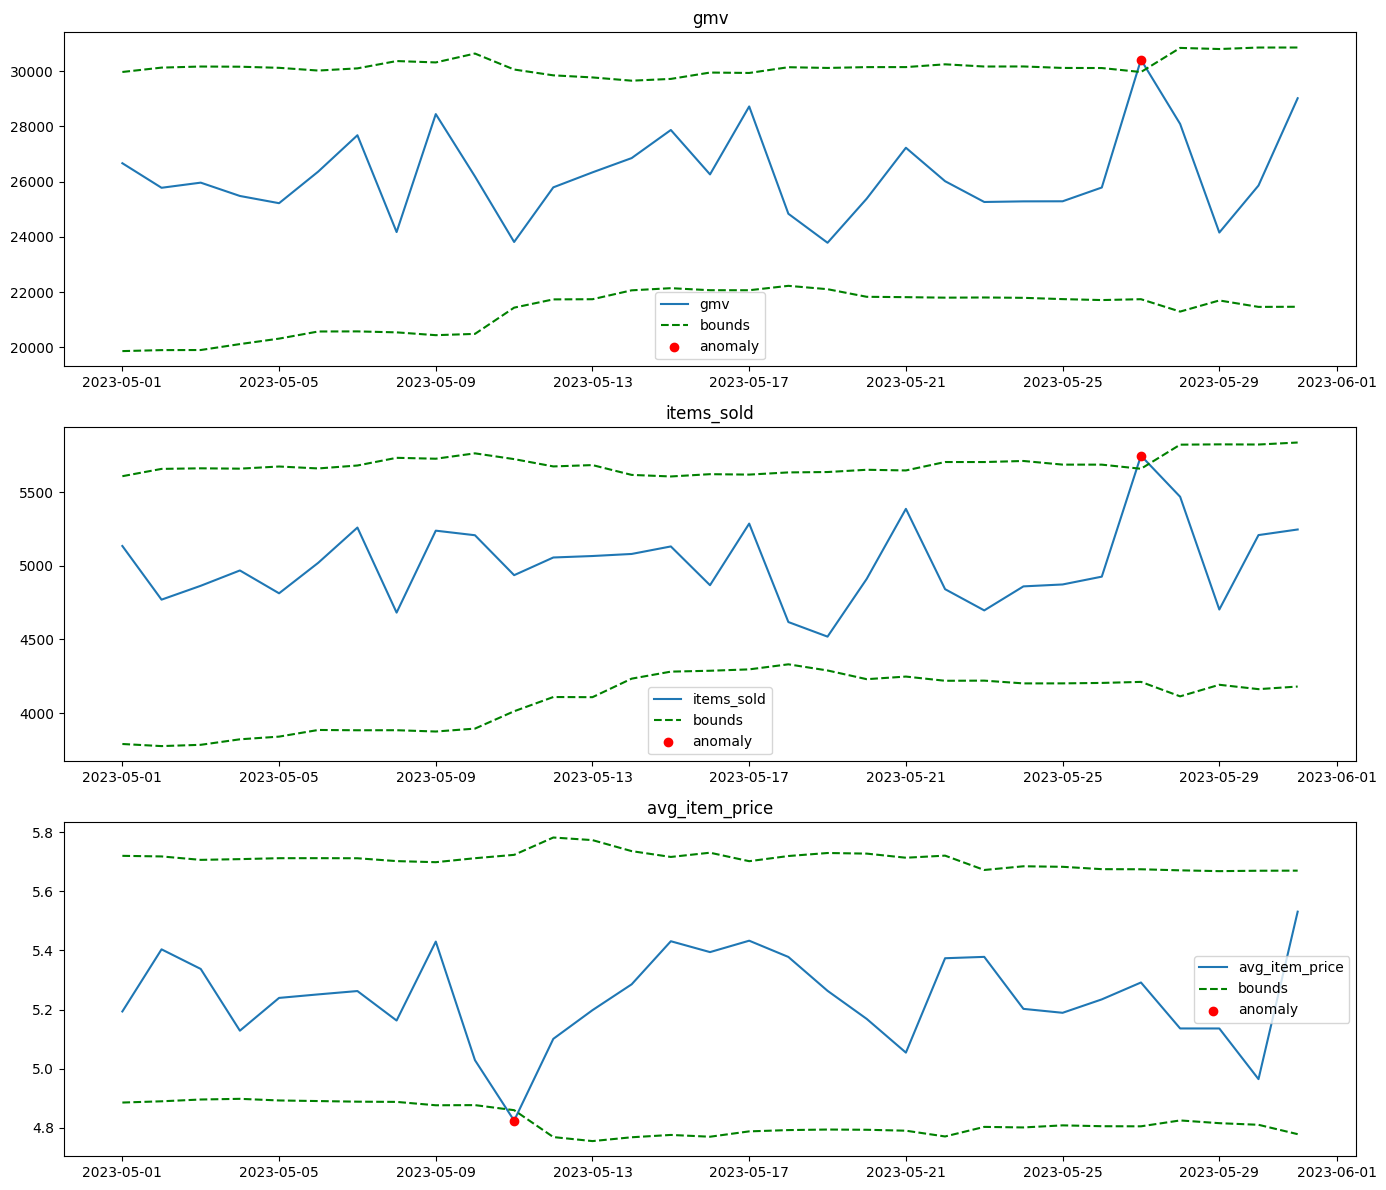

In [7]:
metrics = ['gmv', 'items_sold', 'avg_item_price']

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, metric in zip(axes, metrics):
    res = three_sigma(df, metric)
    may = res[res['date'].dt.month == 5]
    ax.plot(may['date'], may[metric], label=metric)
    ax.plot(may['date'], may['upper'], 'g--', label='bounds')
    ax.plot(may['date'], may['lower'], 'g--')
    ax.scatter(may[may['anomaly']]['date'], may[may['anomaly']][metric], color='red', label='anomaly', zorder=3)
    ax.set_title(metric)
    ax.legend()
plt.tight_layout()
plt.show()

In [8]:
for metric in metrics:
    res = three_sigma(df, metric)
    print(metric)
    print(res[(res['date'].dt.month == 5) & res['anomaly']][['date', metric, 'lower', 'upper']])


gmv
          date       gmv         lower         upper
146 2023-05-27  30409.92  21742.714493  29963.355507
items_sold
          date  items_sold        lower        upper
146 2023-05-27        5747  4212.010374  5657.989626
avg_item_price
          date  avg_item_price     lower     upper
130 2023-05-11        4.824481  4.859753  5.722935


**Вывод**: в мае правило 3σ нашло 27.05 выброс вверх по GMV и числу проданных товаров одновременно, то есть GMV вырос за счёт количества товаров. По средней цене товара аномалия была 11.05, падение ниже нижней границы. Ширина границ почти не меняется в течение месяца, потому что окно в 28 дней сглаживает дневные колебания.

#### 3. Дельта-ряды — 2 балла

1) Рассчитайте дельты значений текущего дня с предыдущим для каждой метрики, затем примените к полученным дельтам правило 3σ:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты.

2) Постройте графики: дельты метрики + границы контроля + выделенные аномалии.

In [9]:
df_delta = df.copy()
for metric in metrics:
    df_delta[metric] = df[metric].diff()

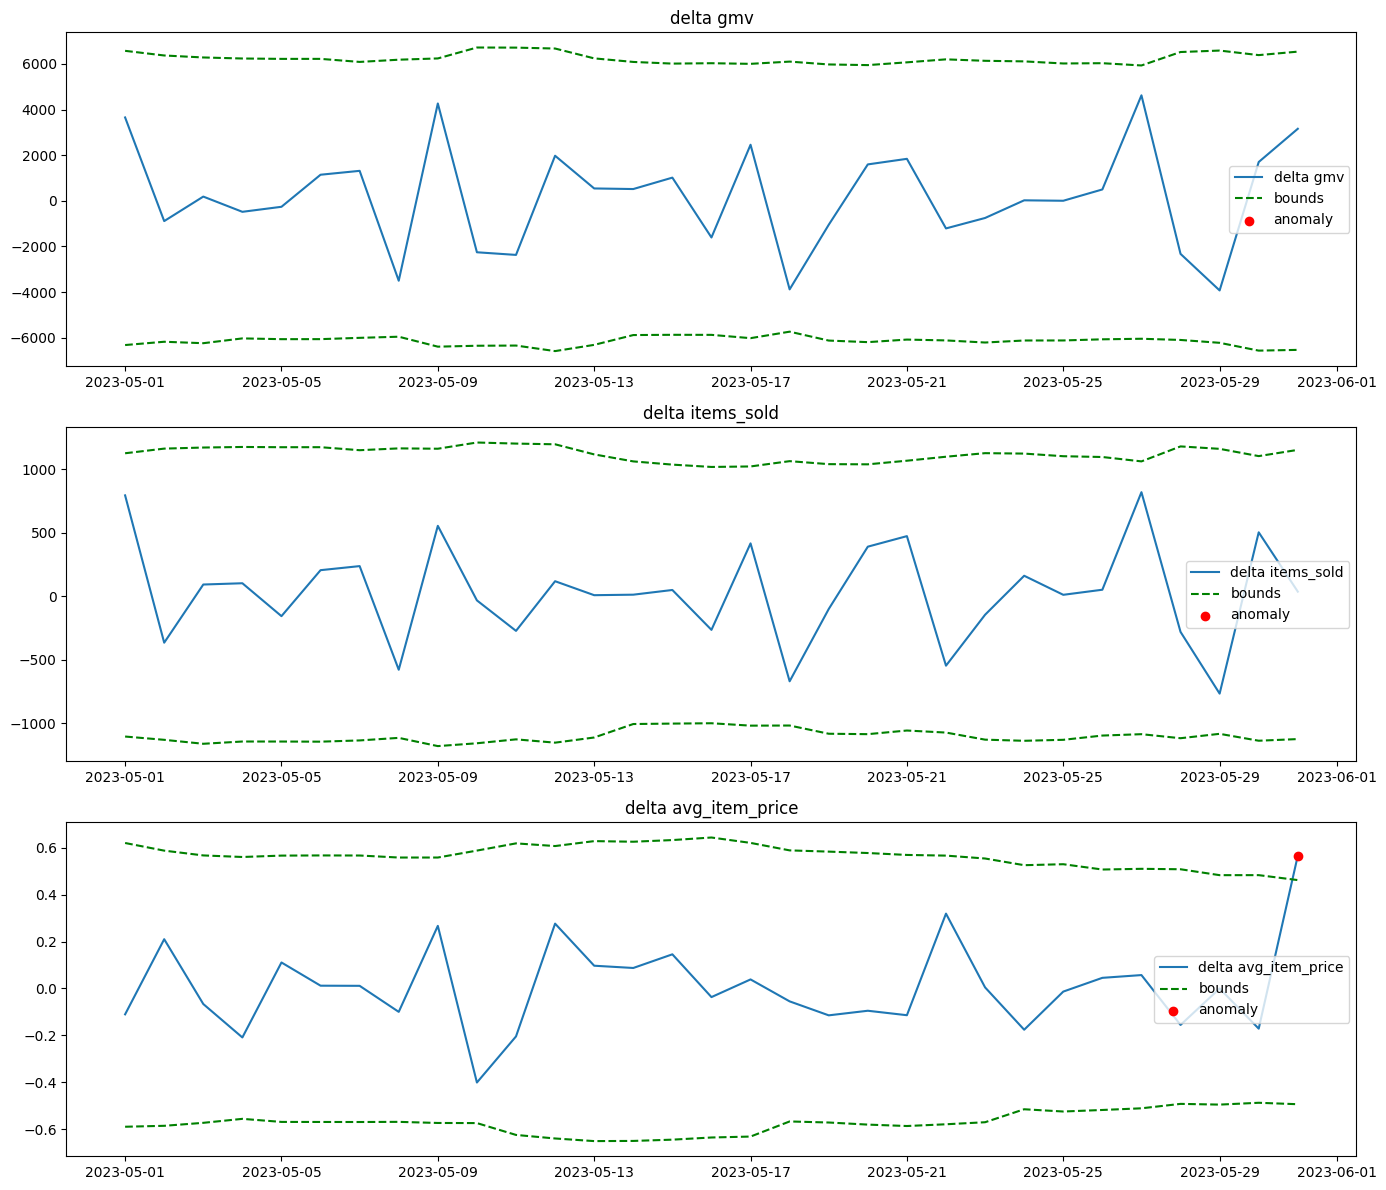

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, metric in zip(axes, metrics):
    res = three_sigma(df_delta, metric)
    may = res[res['date'].dt.month == 5]
    ax.plot(may['date'], may[metric], label='delta ' + metric)
    ax.plot(may['date'], may['upper'], 'g--', label='bounds')
    ax.plot(may['date'], may['lower'], 'g--')
    ax.scatter(may[may['anomaly']]['date'], may[may['anomaly']][metric], color='red', label='anomaly', zorder=3)
    ax.set_title('delta ' + metric)
    ax.legend()
plt.tight_layout()
plt.show()

In [11]:
for metric in metrics:
    res = three_sigma(df_delta, metric)
    print(metric)
    print(res[(res['date'].dt.month == 5) & res['anomaly']][['date', metric, 'lower', 'upper']])

gmv
Empty DataFrame
Columns: [date, gmv, lower, upper]
Index: []
items_sold
Empty DataFrame
Columns: [date, items_sold, lower, upper]
Index: []
avg_item_price
          date  avg_item_price     lower     upper
150 2023-05-31        0.566188 -0.493384  0.462041


**Вывод**: на дельта-рядах в мае нашлась только одна аномалия: резкий рост средней цены товара 31.05 относительно предыдущего дня. Всплески GMV и числа товаров 27.05 и падение средней цены 11.05, которые ловило обычное правило 3σ, на дельтах не детектируются. Дельта показывает только изменение к прошлому дню, а у дельт большая дисперсия, поэтому границы получаются широкими. Зато дельта-ряд лучше ловит резкие скачки и не реагирует на плавный тренд уровня метрики.

#### 4. Generalized ESD — 2 балла

1) Реализуйте Generalized ESD. Обратите внимание, с какими данными работает метод — онлайн или батч? Учтите это в реализации.
2) Найдите аномалии для дельт каждой метрики ЗА МАЙ (используйте данные, полученные на прошлом шаге):
- gmv;
- items_sold;
- avg_item_price.
3) Сравните результаты с правилом 3σ на дельтах: разошлись ли методы?

*Советую обернуть Generalized ESD в функцию, она пригодится на следующем шаге.*

In [12]:
def generalized_esd(x, max_anomalies=5, alpha=0.05):
    x = pd.Series(x).copy()
    n = len(x)
    removed = []
    n_anomalies = 0
    for i in range(1, max_anomalies + 1):
        dev = (x - x.mean()).abs()
        idx = dev.idxmax()
        r = dev[idx] / x.std()
        p = 1 - alpha / (2 * (n - i + 1))
        t_crit = t.ppf(p, n - i - 1)
        lam = (n - i) * t_crit / np.sqrt((n - i - 1 + t_crit ** 2) * (n - i + 1))
        removed.append(idx)
        if r > lam:
            n_anomalies = i
        x = x.drop(idx)
    return removed[:n_anomalies]

In [13]:
may_delta = df_delta[df_delta['date'].dt.month == 5].set_index('date')

for metric in metrics:
    print(metric, generalized_esd(may_delta[metric]))

gmv []
items_sold []
avg_item_price [Timestamp('2023-05-31 00:00:00')]


**Вывод**: Generalized ESD работает с батчем данных, а не онлайн: он смотрит сразу на весь ряд и по очереди проверяет самые сильные отклонения. Поэтому я применял его сразу ко всем дельтам за май, без скользящего окна. Параметры: alpha = 0.05, максимум 5 аномалий.

Методы не разошлись: и GESD, и 3σ на дельтах нашли в мае только скачок средней цены товара 31.05, а по GMV и числу проданных товаров аномалий нет ни одним методом.

#### 5. STL-разложение — 2 балла

1) Для каждой метрики выполните STL-разложение с недельной сезонностью (7 дней) на данных всего датасета:
- gmv;
- items_sold;
- avg_item_price.

Используйте STL из библиотеки statsmodels (уже есть в импортах).
  
2) Для каждой метрики визуализируйте компоненты: тренд, сезонность, остатки (на всем датасете).

4) На остатках примените Generalized ESD, можете использовать функцию из прошлого шага. Это упражнение проделываем только на данных ЗА МАЙ.

5) Подумайте, для каждой ли метрики имеет смысл использовать STL, везде ли визуально присутствуют тренд и недельная сезонность?

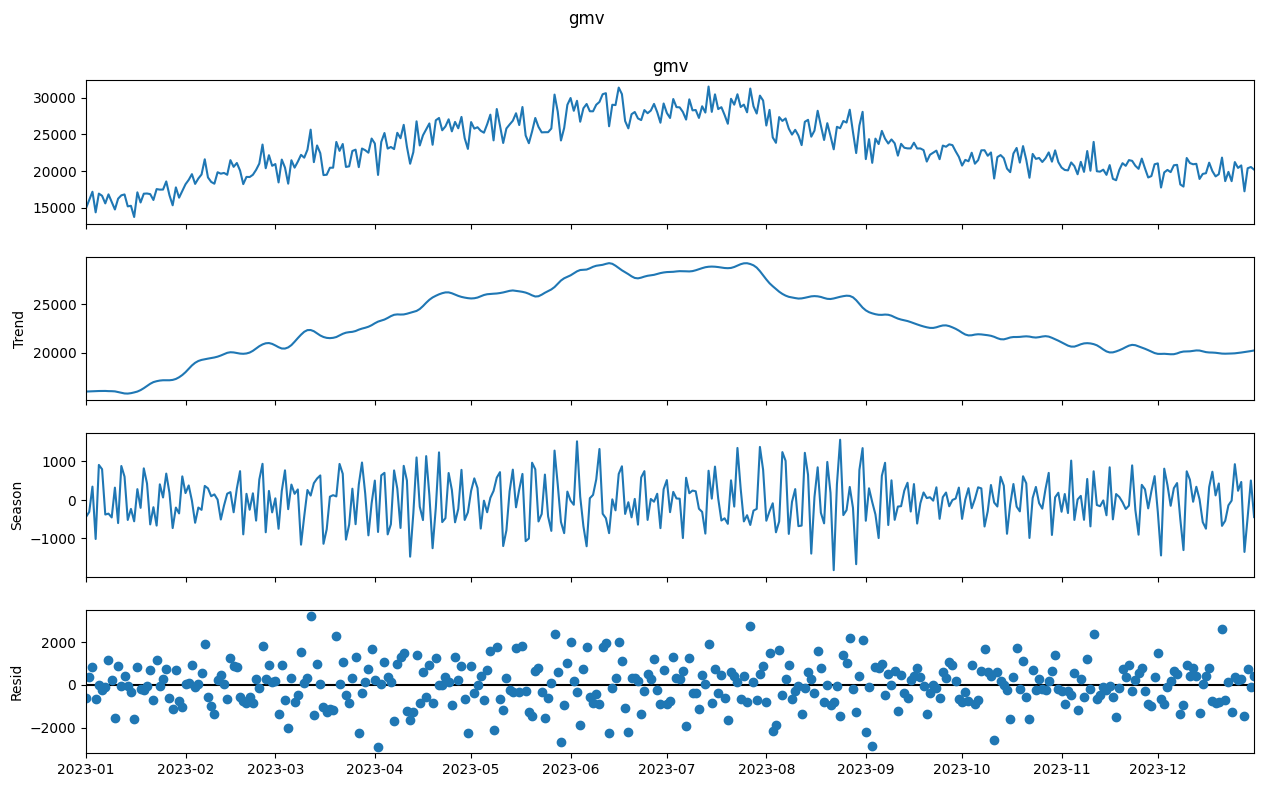

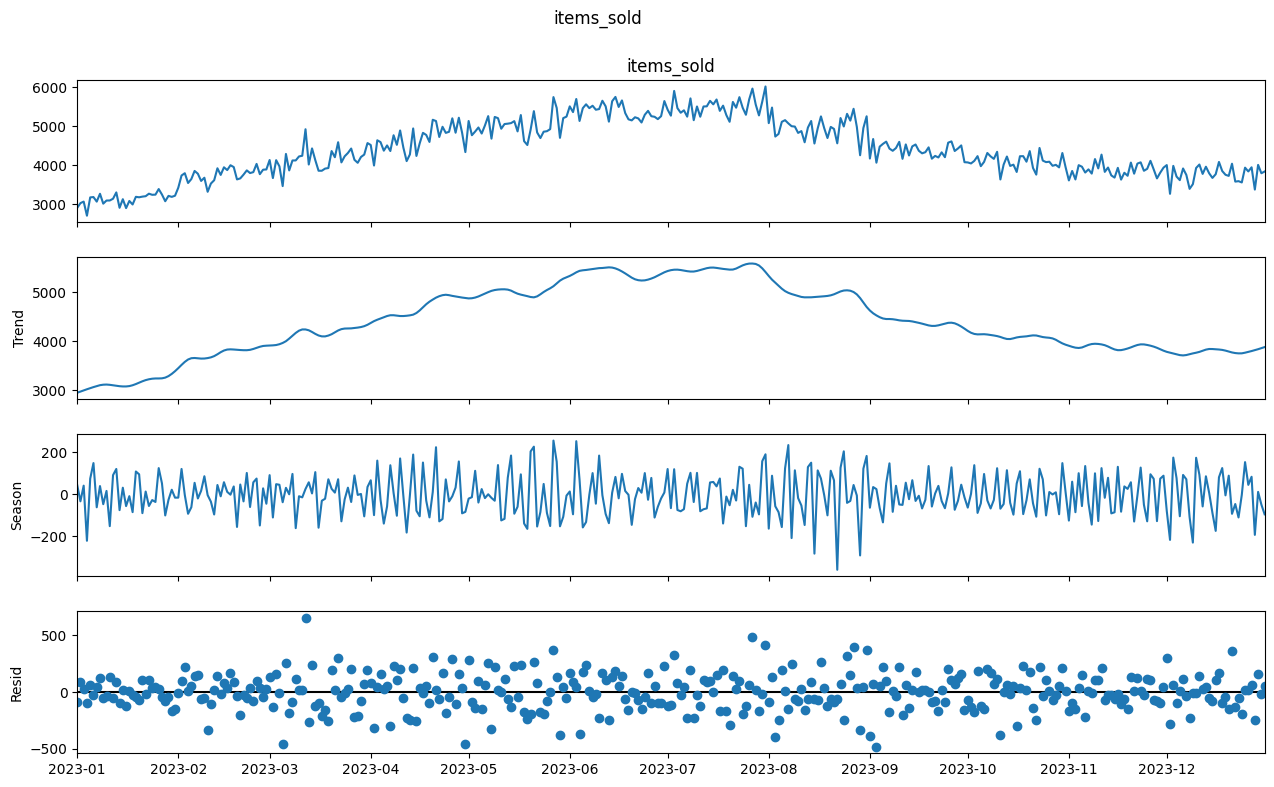

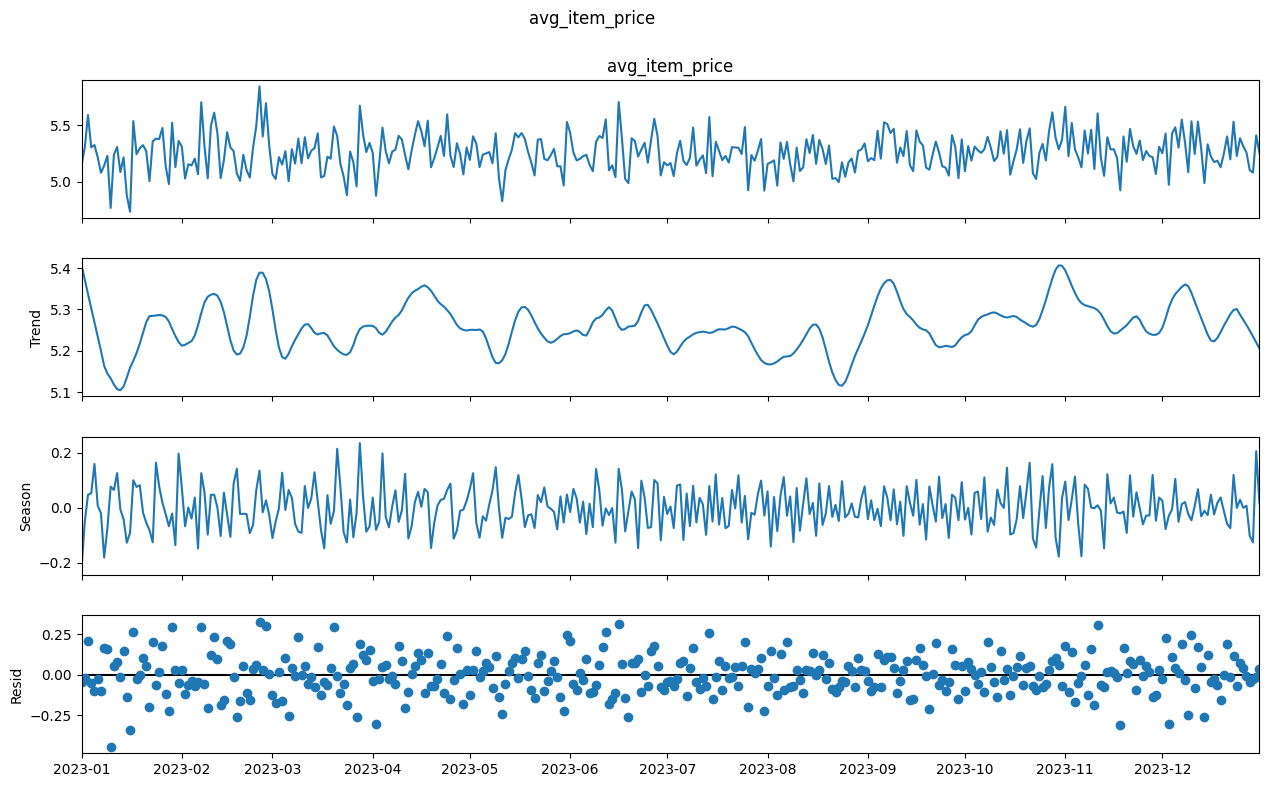

In [14]:
stl_res = {}
for metric in metrics:
    res = STL(df.set_index('date')[metric], period=7).fit()
    stl_res[metric] = res
    fig = res.plot()
    fig.set_size_inches(14, 8)
    fig.suptitle(metric, y=1.01)
    plt.show()

In [15]:
for metric in metrics:
    resid = stl_res[metric].resid
    resid_may = resid[resid.index.month == 5]
    print(metric, generalized_esd(resid_may))

gmv []
items_sold []
avg_item_price []


In [16]:
for metric in metrics:
    ratio = df[metric] / df[metric].rolling(7, center=True).mean()
    print(metric, ratio.groupby(df['date'].dt.dayofweek).mean().round(3).tolist())

gmv [1.004, 0.998, 1.0, 0.998, 0.999, 1.003, 0.996]
items_sold [1.009, 0.989, 0.999, 1.002, 1.0, 0.997, 1.001]
avg_item_price [0.994, 1.009, 1.001, 0.995, 0.999, 1.006, 0.995]


**Вывод**: на остатках STL за май Generalized ESD не нашёл аномалий ни по одной метрике. После удаления тренда и сезонности оставшиеся колебания в мае выглядят как обычный шум.

У GMV и числа проданных товаров есть явный тренд: рост с января до пика летом (июнь-июль) и потом снижение к концу года. Для них STL полезен, чтобы убрать тренд. У средней цены товара тренда нет, она колеблется около 5.1-5.4 весь год.

Недельной сезонности визуально нет ни у одной метрики. Сезонная компонента на графиках выглядит как шум без повторяющегося паттерна, а средние отклонения по дням недели меньше 1%. Получается, что STL с периодом 7 имеет смысл только для GMV и числа товаров, и то в основном из-за тренда. Для средней цены товара STL не нужен, можно искать аномалии прямо по исходному ряду.

#### 6. EWMA — 2 балла

1) Реализуйте метод EWMA для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Сглаженная статистика считается рекуррентно с параметром $\lambda = 0.2$:

$$
z_t = \lambda x_t + (1-\lambda)\, z_{t-1}, \qquad z_0 = x_0,
$$

где $x_t$ — исходное дневное значение метрики. В pandas это делает [встроенная функция экспоненциального сглаживания](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html) — обратите внимание на параметр `adjust=False`, именно он дает рекуррентную форму выше.

Контрольные границы задаются как

$$
\mu_t \pm L\,\sigma_t \sqrt{\frac{\lambda}{2-\lambda}}, \qquad L = 3.
$$

Здесь $\mu_t$ и $\sigma_t$ — среднее и стандартное отклонение **исходного ряда $x_t$**, а не сглаженного $z_t$, посчитанные на скользящем окне 28 дней. Множитель $\sqrt{\lambda/(2-\lambda)}$ — асимптотическое приближение отношения дисперсии сглаженной статистики к дисперсии сырых наблюдений: он уже учитывает, что $z_t$ колеблется меньше, чем $x_t$, поэтому подставлять в формулу разброс самого $z_t$ нельзя — сжатие применится дважды, и коридор получится слишком узким.

Окно для $\mu_t$ и $\sigma_t$ должно заканчиваться на предыдущем дне (`.rolling(28).mean().shift(1)`), иначе текущее наблюдение попадёт в собственную оценку разброса и аномалия спрячет сама себя.

2) Постройте графики: сглаженная метрика + границы контроля + выделенные аномалии.
3) Напишите, какой из подходов вам больше всего понравился для онлайн-мониторинга, а какой — для ретроспективного анализа, и почему. Тут нет правильного ответа :)

In [17]:
def ewma(df, metric, lam=0.2, L=3, window=28):
    res = df[['date', metric]].copy()
    res['z'] = res[metric].ewm(alpha=lam, adjust=False).mean()
    mu = res[metric].rolling(window).mean().shift(1)
    sigma = res[metric].rolling(window).std().shift(1)
    res['upper'] = mu + L * sigma * np.sqrt(lam / (2 - lam))
    res['lower'] = mu - L * sigma * np.sqrt(lam / (2 - lam))
    res['anomaly'] = (res['z'] > res['upper']) | (res['z'] < res['lower'])
    return res

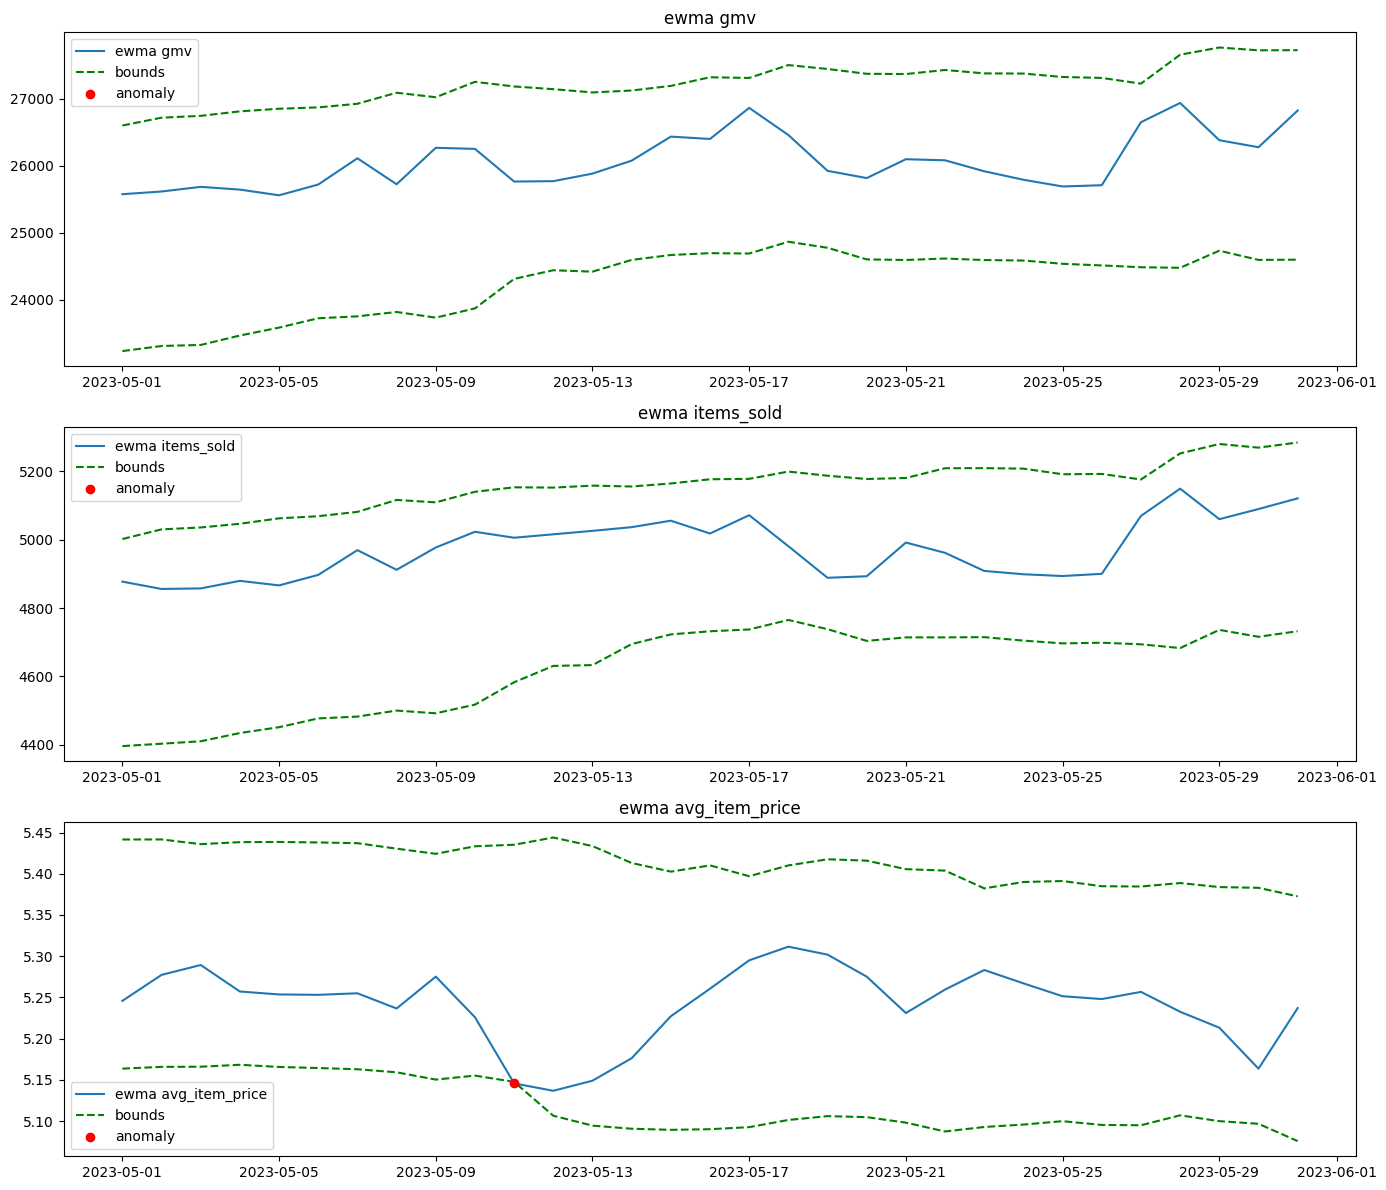

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, metric in zip(axes, metrics):
    res = ewma(df, metric)
    may = res[res['date'].dt.month == 5]
    ax.plot(may['date'], may['z'], label='ewma ' + metric)
    ax.plot(may['date'], may['upper'], 'g--', label='bounds')
    ax.plot(may['date'], may['lower'], 'g--')
    ax.scatter(may[may['anomaly']]['date'], may[may['anomaly']]['z'], color='red', label='anomaly', zorder=3)
    ax.set_title('ewma ' + metric)
    ax.legend()
plt.tight_layout()
plt.show()

In [19]:
for metric in metrics:
    res = ewma(df, metric)
    print(metric)
    print(res[(res['date'].dt.month == 5) & res['anomaly']][['date', metric, 'z', 'lower', 'upper']])

gmv
Empty DataFrame
Columns: [date, gmv, z, lower, upper]
Index: []
items_sold
Empty DataFrame
Columns: [date, items_sold, z, lower, upper]
Index: []
avg_item_price
          date  avg_item_price         z    lower     upper
130 2023-05-11        4.824481  5.145622  5.14748  5.435207


**Вывод**: EWMA в мае нашёл только падение средней цены товара 11.05, то же, что и обычное правило 3σ. Всплеск GMV и числа товаров 27.05 EWMA не поймал: это был одиночный скачок, а сглаженная статистика реагирует на него слабо. Зато EWMA лучше подходит для ловли небольших, но устойчивых сдвигов, которые длятся несколько дней.

Для онлайн-мониторинга мне больше понравился EWMA. Он считается просто и быстро и меньше дёргается из-за единичного шума, поэтому будет меньше ложных алертов. При этом он хорошо замечает, когда метрика постепенно уезжает. Для резких одиночных падений его можно дополнить обычным правилом 3σ.

Для ретроспективного анализа мне больше понравилась связка STL + Generalized ESD. В батче можно сначала убрать тренд (у GMV и числа товаров он сильный), а потом GESD сам определит, сколько выбросов в ряду, без ручного подбора окна. Для метрик без тренда и сезонности, как средняя цена товара, можно применять GESD сразу к исходному ряду или к дельтам.